# Pal et al. 2021 — Breast Cancer (10x)
## 01 · Preprocessing → malignant cell-state manifold

Load the five 3CA group leaves, select malignant cells, threshold under-populated samples, integrate
samples with Harmony, embed, remove detached islands, and resolve the manifold's sub-regions. **Gate 1**
is judged on the regenerated embedding (per-neighbourhood iLISI + connected components), and each
sub-region's biology (cell cycle + embryonic signatures) is settled before the GO.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad, scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())                    # Pal2021_Breast
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Breast
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Pal2021_Breast | category: Breast


### Load malignant cells
The dataset ships expression split across five `Group*` leaves (shared `Genes.txt`); load each with the
custom 3CA loader (UMI counts → `normalize_total` → `log1p`) and concatenate. `celltype=='Malignant'`
selects the tumour compartment the publication annotated.

In [3]:
leaves = sorted(glob.glob(os.path.join(pth_in, 'Group*')))
from scripts.load import load_CCCA_adata
adata = ad.concat([load_CCCA_adata(l, verbose=False) for l in leaves], join='outer', merge='same')
adata.var_names_make_unique()
print('full atlas (all leaves):', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples with malignant cells:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

full atlas (all leaves): (305224, 33538)
malignant: (59374, 33538) | samples with malignant cells: 26
expression: X max 7.15 (log1p of normalize_total UMI counts)


### Sample threshold — data-derived gap-finding
Sort per-sample malignant counts and look for a *dominant spillover cliff* (a single count ratio far
larger than the runner-up, dropping into the sub-100 tail). If present, threshold at the geometric mean
of that cliff; otherwise fall back to a floor of 100. Here a real cliff exists (a handful of samples
contribute 1–3 malignant cells — doublet/ambient spillover), so the geometric-mean rule keeps the
well-populated tumours and drops the specks.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
thresh = int(np.sqrt(vals[gap]*vals[gap+1])) if dominant else FLOOR
print(('dominant spillover cliff -> geometric-mean threshold = %d' % thresh) if dominant
      else ('no dominant cliff -> floor >= %d' % thresh))
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'Triple_negative_0135': np.int64(13252), 'ER_positive_0029_9C': np.int64(6064), 'Triple_negative_BRCA1_4031': np.int64(5032), 'Triple_negative_BRCA1_0131': np.int64(4553), 'HER2_0337': np.int64(3583), 'HER2_0176': np.int64(3169), 'ER_positive_0167': np.int64(3053), 'HER2_0308': np.int64(2876), 'HER2_0161': np.int64(2776), 'ER_positive_0173': np.int64(2190), 'ER_positive_0043': np.int64(2040), 'ER_positive_0029_7C': np.int64(2006), 'ER_positive__LN_0056': np.int64(1830), 'ER_positive_0360': np.int64(1579), 'HER2_0331': np.int64(1410), 'Triple_negative_0126': np.int64(1185), 'ER_positive_LN_0173': np.int64(771), 'ER_positive_LN_0068': np.int64(691), 'Triple_negative_BRCA1_0554': np.int64(563), 'PR_positive_0319': np.int64(451), 'ER_positive_LN_0167': np.int64(237), 'ER_positive_0056': np.int64(56), 'Triple_negative_0106': np.int64(3), 'Triple_negative_0114': np.int64(2), 'ER_positive_0025': np.int64(1), 'Triple_negative_BRCA1_0177': np.int64(1)}
argmax gap 56->

### Genes → PCA → Harmony integration
Overdispersed-gene selection (scFates GAM), PCA, then Harmony on `sample`. Integration strength is
**swept** (θ=2/5/10) and judged by the same-sample neighbour fraction (lower = better mixed): mixing
improves sharply from θ=2 to θ=5 then flattens, so θ=10 is chosen (strongest integration without
collapsing structure) for the 22-tumour batch effect.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
def _same_frac(rep):
    idx = NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    s = adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))
base = _same_frac(adata.obsm['X_pca'][:,:20]); sweep={}
for th in [2,5,10]:
    sce.pp.harmony_integrate(adata,'sample',theta=th,max_iter_harmony=30,random_state=SEED)
    sweep[th] = _same_frac(adata.obsm['X_pca_harmony'][:,:20])
print('same-sample neighbour fraction | pre-Harmony %.3f' % base, '| sweep', {k:round(v,3) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing improves sharply to theta=5 then flattens; strongest integration chosen)')
sce.pp.harmony_integrate(adata,'sample',theta=theta,max_iter_harmony=30,random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 3733 over-dispersed features (0:00:09) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 3733
same-sample neighbour fraction | pre-Harmony 0.983 | sweep {2: 0.51, 5: 0.428, 10: 0.426}
selected theta = 10 (mixing improves sharply to theta=5 then flattens; strongest integration chosen)


### Island removal — radius graph, keep the largest component
Build a UMAP radius graph at 6× the median nearest-neighbour distance and keep the largest connected
component, stripping only cleanly-detached specks (conservative).

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('manifold after island removal:', adata.shape[0], 'cells')

removed 11 cells in 4 detached islands
manifold after island removal: 59356 cells


### Sub-region identity — **biology before geometry**
The integrated manifold resolves (Leiden res=0.15) into two lobes. Settle their biology *before* Gate 1:
cell-cycle phase, a proliferation-gene score, and the embryonic signatures per lobe. One lobe is a
**proliferation compartment** (majority cycling, high proliferation score) — the classic confound where
gastrulation/somitogenesis scores ride on cell-cycle genes. It is labelled `Cycling` and the developmental
trajectory (02) is scoped to the low-cycling `Body`, the sub-region that reproduces the reference
signature relationships without proliferation confound.

In [7]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
print('proliferation score per lobe:', adata.obs.groupby('lobe',observed=True)['prolif_score'].mean().round(3).to_dict())
cyc_by_lobe = adata.obs.groupby('lobe',observed=True)['cycling'].mean()
cyc_lobe = cyc_by_lobe.idxmax()
adata.obs['compartment'] = np.where(adata.obs['lobe']==cyc_lobe, 'Cycling', 'Body')
adata.obs['compartment'] = adata.obs['compartment'].astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict(),
      '| Cycling lobe =', cyc_lobe, '(%.0f%% cycling)' % (100*cyc_by_lobe.max()))

lobe sizes: {'0': 45191, '1': 14165}
cycling fraction per lobe: {'0': 0.063, '1': 0.756}
proliferation score per lobe: {'0': -0.092, '1': 0.357}
compartments: {'Body': 45191, 'Cycling': 14165} | Cycling lobe = 1 (76% cycling)


### Embryonic signatures + house orientation
Score Gast / pSom / Crest with the union control pool, graph-smooth for spatial reads, and confirm the
per-lobe pattern: pSom (and its inverse Crest) define the embryonic axis, and **raw pSom is elevated in
the Cycling lobe** (pSom↔proliferation confound) — the reason that lobe is excluded from the trajectory.
A rigid rotation stores a house linear layout `X_umap_lin` oriented along the pSom→Crest biological axis
(distances preserved), shared by every panel.

In [8]:
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
    print(f'{l}: {g.size}/{feat[src].size} genes present')
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j,l in enumerate(['Gast','pSom','Crest']): adata.obs[l+'_sm'] = S[:,j]
print('raw module means (honest readout):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
print('raw pSom per lobe:', adata.obs.groupby('lobe',observed=True)['pSom'].mean().round(3).to_dict(),
      '| pSom vs prolif r = %.2f (confound)' % np.corrcoef(adata.obs['pSom'], adata.obs['prolif_score'])[0,1])
# house orientation: horizontal = pSom->Crest biological axis, origin (pSom-high) on left
xy = adata.obsm['X_umap']; cxy = xy - xy.mean(0)
dfield = adata.obs['Crest_sm'].values - adata.obs['pSom_sm'].values      # increases origin->terminus
u = np.array([np.cov(cxy[:,0], dfield)[0,1], np.cov(cxy[:,1], dfield)[0,1]]); u = u/np.linalg.norm(u)
ang = np.arctan2(u[1], u[0])
Rm = np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]])
xyr = cxy @ Rm.T
if np.corrcoef(xyr[:,0], dfield)[0,1] < 0: xyr[:,0] = -xyr[:,0]   # origin -> left
adata.obsm['X_umap_lin'] = xyr
print('house orientation stored as X_umap_lin (pSom origin left, Crest terminus right);',
      'corr(x_lin, Crest-pSom) = %.2f' % np.corrcoef(xyr[:,0], dfield)[0,1])

Gast: 80/81 genes present
pSom: 94/98 genes present
Crest: 103/104 genes present
raw module means (honest readout): {'Gast': -0.0068, 'pSom': 0.0358, 'Crest': -0.0337}
raw pSom per lobe: {'0': 0.029, '1': 0.056} | pSom vs prolif r = 0.37 (confound)
house orientation stored as X_umap_lin (pSom origin left, Crest terminus right); corr(x_lin, Crest-pSom) = 0.83


### Gate 1 — mixing + continuity on the regenerated embedding
Judged on the embedding, not a single scalar: **per-neighbourhood iLISI** (median effective number of
samples among 90 neighbours) quantifies mixing, and **connected components** confirm one continuous mass.
The manifold is sample-integrated (iLISI rises from ~1 to ~5 of 22 samples) and continuous (one component;
only a few specks removed). It contains a proliferation compartment, resolved above — the trajectory is
scoped to the developmental `Body`. **Gate 1 → GO.**

In [9]:
n_samp = adata.obs['sample'].nunique()
def _ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
il_pre  = np.median(_ilisi(adata.obsm['X_pca'][:,:20], adata.obs['sample'].values))
il_post = np.median(_ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta=10) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (largest connected component).')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold ->',
      'PASS (trajectory scoped to the low-cycling Body; Cycling compartment excluded from the fit)')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.96 of 22 samples
22 samples share one continuous manifold (largest connected component).
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> PASS (trajectory scoped to the low-cycling Body; Cycling compartment excluded from the fit)


### Save processed manifold

In [10]:
protect = {'sample','compartment','lobe','celltype','cell_type','cell_cycle_phase','source','disease','patient'}
for col in adata.obs.columns:
    if col in protect:
        adata.obs[col] = adata.obs[col].astype(str).astype('category'); continue
    s = adata.obs[col]
    if s.dtype == object:
        conv = pd.to_numeric(s, errors='coerce')
        adata.obs[col] = conv if (s.notna().sum()>0 and conv.notna().sum()>=0.9*s.notna().sum()) else s.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (59356, 26383)


### Figure — sample integration (Gate 1 deliverable)
Whole malignant manifold on the house linear layout, coloured by `sample`: intermixing across the
embedding is the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 59356 | samples: 22


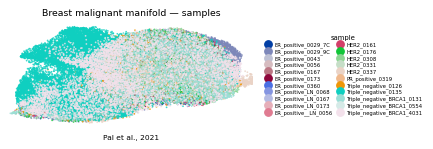

In [11]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=8, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.2, fontsize=4.2, columnspacing=.5, title='sample', title_fontsize=5.5)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Breast malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Pal et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0], '| samples:', plot.obs['sample'].nunique())